In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import re 
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS 
from collections import Counter

In [4]:
df = pd.read_csv("fakenews.csv")

In [5]:
# Handle missing text 
df["headline"] = df["headline"].fillna("").astype(str) 
df["body_text"] = df["body_text"].fillna("").astype(str)

In [6]:
# Combine headline and body text 
df["text"] = df["headline"] + " " + df["body_text"] 
df["word_count"] = df["text"].apply( lambda x: len(x.split()) )

In [7]:
# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Calculate word count
df["word_count"] = df["text"].apply(lambda x: len(x.split()))

# Calculate character count
df["character_count"] = df["text"].apply(len)

# Calculate stopword frequency
stopwords = set(ENGLISH_STOP_WORDS)

In [8]:
def count_stopwords(text):
    words = re.findall(r"\b[a-zA-Z]+\b", text.lower())
    return sum(word in stopwords for word in words)

df["stopword_count"] = df["text"].apply(count_stopwords)

# Statistical analysis by label
print("\nStatistical Analysis of Real and Fake News:")
print(
    df.groupby("label")[
        ["word_count", "character_count", "stopword_count"]
    ].agg(["mean", "median", "std", "min", "max"]).round(2)
)

# Overall statistical summary
print("\nOverall Statistical Summary:")
print(
    df[["word_count", "character_count", "stopword_count"]]
    .describe()
    .round(2)
)


Statistical Analysis of Real and Fake News:
      word_count                      character_count                         \
            mean median   std min max            mean median    std min  max   
label                                                                          
Fake       15.44   15.0  2.00  12  21          105.95  104.0  14.30  77  150   
Real       15.30   15.0  1.92  12  21          104.16  103.0  14.42  77  150   

      stopword_count                       
                mean median   std min max  
label                                      
Fake            5.11    5.0  1.58   2   8  
Real            5.05    5.0  1.53   2   8  

Overall Statistical Summary:
       word_count  character_count  stopword_count
count     2212.00          2212.00         2212.00
mean        15.37           105.06            5.08
std          1.96            14.38            1.56
min         12.00            77.00            2.00
25%         14.00            95.00            4.0

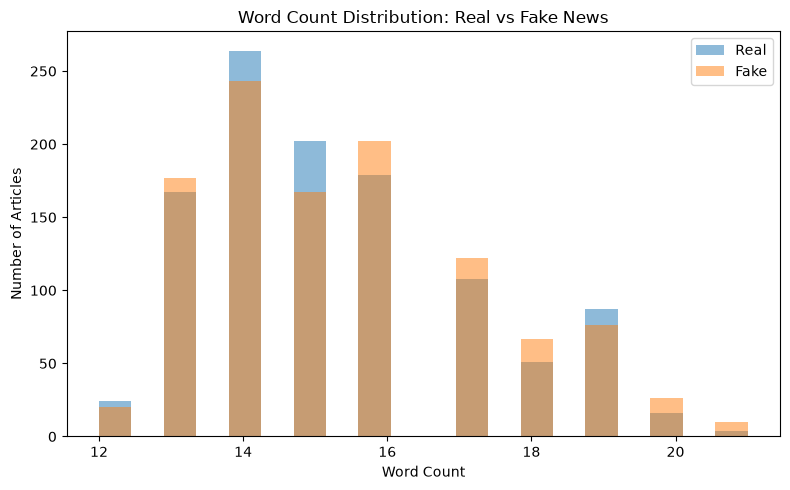

In [9]:
# Word count distribution
plt.figure(figsize=(8, 5))

for label in df["label"].dropna().unique():
    plt.hist(
        df.loc[df["label"] == label, "word_count"],
        alpha=0.5,
        label=label,
        bins=20
    )

plt.title("Word Count Distribution: Real vs Fake News")
plt.xlabel("Word Count")
plt.ylabel("Number of Articles")
plt.legend()
plt.tight_layout()
plt.show()

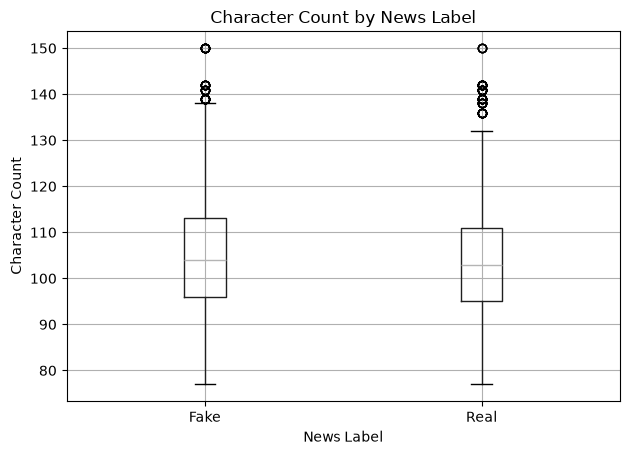

In [10]:
# Character count comparison
df.boxplot(column="character_count", by="label")
plt.title("Character Count by News Label")
plt.suptitle("")
plt.xlabel("News Label")
plt.ylabel("Character Count")
plt.tight_layout()
plt.show()


In [11]:
# Stopword frequency by label
for label in df["label"].dropna().unique():
    words = re.findall(
        r"\b[a-zA-Z]+\b",
        " ".join(df.loc[df["label"] == label, "text"]).lower()
    )

    counts = Counter(word for word in words if word in stopwords)

    print(f"\nTop 10 Stopwords in {label} News:")
    print(counts.most_common(10))



Top 10 Stopwords in Real News:
[('the', 1235), ('in', 436), ('a', 215), ('it', 212), ('this', 211), ('an', 209), ('are', 208), ('of', 203), ('that', 199), ('from', 191)]

Top 10 Stopwords in Fake News:
[('the', 1254), ('in', 442), ('from', 255), ('of', 249), ('this', 243), ('a', 233), ('are', 230), ('that', 225), ('it', 220), ('an', 208)]


In [12]:
# Text length variability
print("\nText Length Variability by Label:")
print(
    df.groupby("label")[
        ["word_count", "character_count"]
    ].std().round(2)
)


Text Length Variability by Label:
       word_count  character_count
label                             
Fake         2.00            14.30
Real         1.92            14.42


In [13]:
# Save results
df.to_csv("fakenews_text_analysis.csv", index=False)

print("\nAnalysis completed successfully!")
print("Results saved to fakenews_text_analysis.csv")


Analysis completed successfully!
Results saved to fakenews_text_analysis.csv
